A warehouse contains 20 electronic components, of which 6 are defective and 14 are non-defective. A quality inspector randomly selects 5 components without replacement.

Let \(X\) be the number of defective components selected.

Write a Python program to:

(a) Identify the distribution, its parameters and possible values of \(X\).

(b) Simulate 20,000 samples, selecting 5 components without replacement in each sample.

(c) Calculate the empirical and theoretical PMFs and display them in a table.

(d) Plot the empirical and theoretical PMFs for comparison.

(e) Calculate the empirical and theoretical expectation and variance.

(f) Calculate the probability that at least 2 selected components are defective, both empirically and theoretically.

Distribution: Hypergeometric
Total population (N): 20
Defective components (K): 6
Sample size (n): 5
Possible values: [0 1 2 3 4 5]

Empirical vs Theoretical PMF:
 x  Empirical PMF  Theoretical PMF
 0         0.1314           0.1291
 1         0.3818           0.3874
 2         0.3567           0.3522
 3         0.1168           0.1174
 4         0.0126           0.0135
 5         0.0007           0.0004


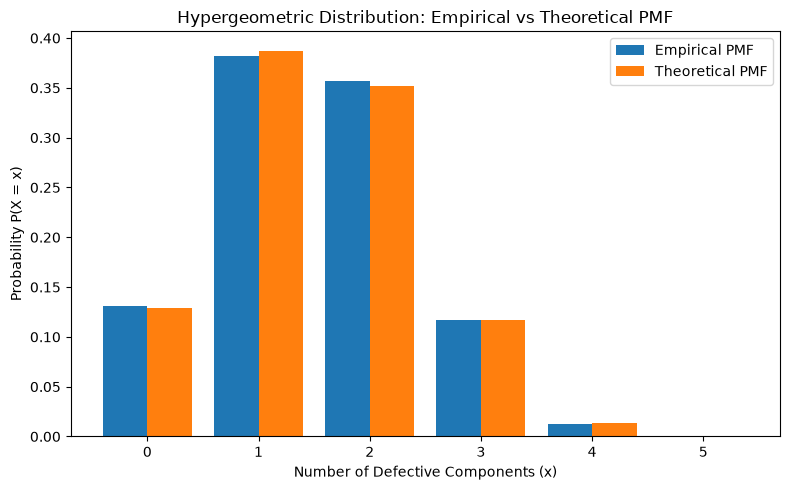


Expectation and Variance:
        Empirical  Theoretical
E[X]       1.4995       1.5000
Var(X)     0.8304       0.8289

Probability P(X >= 2):
Simulated probability = 0.4868
Theoretical probability = 0.4835


In [1]:

# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

# Given parameters
N = 20
K = 6
n = 5
M = 20000

# (a) Identify distribution and possible values
print("Distribution: Hypergeometric")
print("Total population (N):", N)
print("Defective components (K):", K)
print("Sample size (n):", n)

x = np.arange(max(0, n - (N - K)), min(n, K) + 1)
print("Possible values:", x)

# (b) Simulate samples without replacement
rng = np.random.default_rng(42)

X = rng.hypergeometric(
    ngood=K,
    nbad=N - K,
    nsample=n,
    size=M
)

# (c) Calculate empirical and theoretical PMF
emp = np.array([(X == k).mean() for k in x])
theo = stats.hypergeom.pmf(x, N, K, n)

pmf_table = pd.DataFrame({
    "x": x,
    "Empirical PMF": emp,
    "Theoretical PMF": theo
})

print("\nEmpirical vs Theoretical PMF:")
print(pmf_table.round(4).to_string(index=False))

# (d) Plot both PMFs
plt.figure(figsize=(8, 5))

plt.bar(x - 0.2, emp, width=0.4, label="Empirical PMF")
plt.bar(x + 0.2, theo, width=0.4, label="Theoretical PMF")

plt.xlabel("Number of Defective Components (x)")
plt.ylabel("Probability P(X = x)")
plt.title("Hypergeometric Distribution: Empirical vs Theoretical PMF")
plt.xticks(x)
plt.legend()
plt.tight_layout()
plt.show()

# (e) Calculate expectation and variance
emp_mean = X.mean()
theo_mean = n * K / N

emp_var = X.var()
theo_var = n * (K / N) * (1 - K / N) * ((N - n) / (N - 1))

statistics_table = pd.DataFrame({
    "Empirical": [emp_mean, emp_var],
    "Theoretical": [theo_mean, theo_var]
}, index=["E[X]", "Var(X)"])

print("\nExpectation and Variance:")
print(statistics_table.round(4))

# (f) Calculate P(X >= 2)
p_sim = (X >= 2).mean()
p_theory = stats.hypergeom.sf(1, N, K, n)

print("\nProbability P(X >= 2):")
print(f"Simulated probability = {p_sim:.4f}")
print(f"Theoretical probability = {p_theory:.4f}")
